Crop Yield Prediction using XGBoost Regressor
================================================
Complete end-to-end pipeline: EDA, preprocessing, training, evaluation,
and rich visualizations.
 
NOTE: Unlike the crop-recommendation dataset, `Yield` here is a CONTINUOUS
number (tons/hectare-ish), so this is a REGRESSION problem, not classification.
We use XGBRegressor instead of XGBClassifier.

#### Importing Dependencies

In [1]:
import warnings
warnings.filterwarnings("ignore")
 
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error
)
 
from xgboost import XGBRegressor
import xgboost as xgb

#### CONFIG

In [3]:
DATA_PATH = "../Dataset/crop_yield.csv"          # <-- update path if needed
OUT_DIR = "outputs"                    # relative folder, created next to notebook/script
os.makedirs(OUT_DIR, exist_ok=True)
print("Saving all outputs to:", os.path.abspath(OUT_DIR))
 
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

Saving all outputs to: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\crop_yield\outputs


#### LOAD DATA

In [4]:
df = pd.read_csv(DATA_PATH)
 
# clean whitespace in string columns (this dataset has trailing spaces e.g. "Kharif     ")
for col in ["Crop", "Season", "State"]:
    df[col] = df[col].str.strip()
 
print("Dataset shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())
print("\nYield stats:\n", df["Yield"].describe())
 
TARGET = "Yield"
CAT_COLS = ["Crop", "Season", "State"]
NUM_COLS = ["Crop_Year", "Area", "Production", "Annual_Rainfall", "Fertilizer", "Pesticide"]

Dataset shape: (19689, 10)
           Crop  Crop_Year      Season  State     Area  Production  \
0      Arecanut       1997  Whole Year  Assam  73814.0       56708   
1     Arhar/Tur       1997      Kharif  Assam   6637.0        4685   
2   Castor seed       1997      Kharif  Assam    796.0          22   
3       Coconut       1997  Whole Year  Assam  19656.0   126905000   
4  Cotton(lint)       1997      Kharif  Assam   1739.0         794   

   Annual_Rainfall  Fertilizer  Pesticide        Yield  
0           2051.4  7024878.38   22882.34     0.796087  
1           2051.4   631643.29    2057.47     0.710435  
2           2051.4    75755.32     246.76     0.238333  
3           2051.4  1870661.52    6093.36  5238.051739  
4           2051.4   165500.63     539.09     0.420909  

Missing values:
 Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yie

#### EXPLORATORY DATA ANALYSIS (EDA) VISUALS

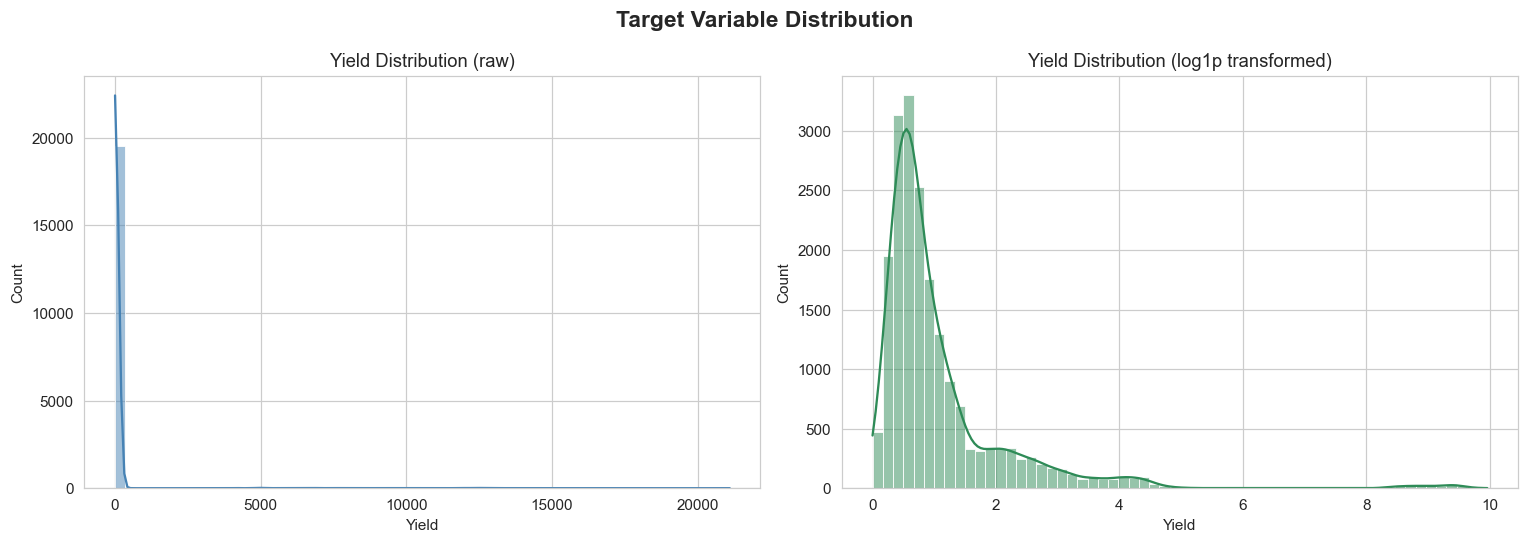

In [5]:
# 2a. Target distribution (raw + log)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df[TARGET], bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Yield Distribution (raw)")
sns.histplot(np.log1p(df[TARGET]), bins=60, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("Yield Distribution (log1p transformed)")
plt.suptitle("Target Variable Distribution", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/01_target_distribution.png")
plt.show()
plt.close()

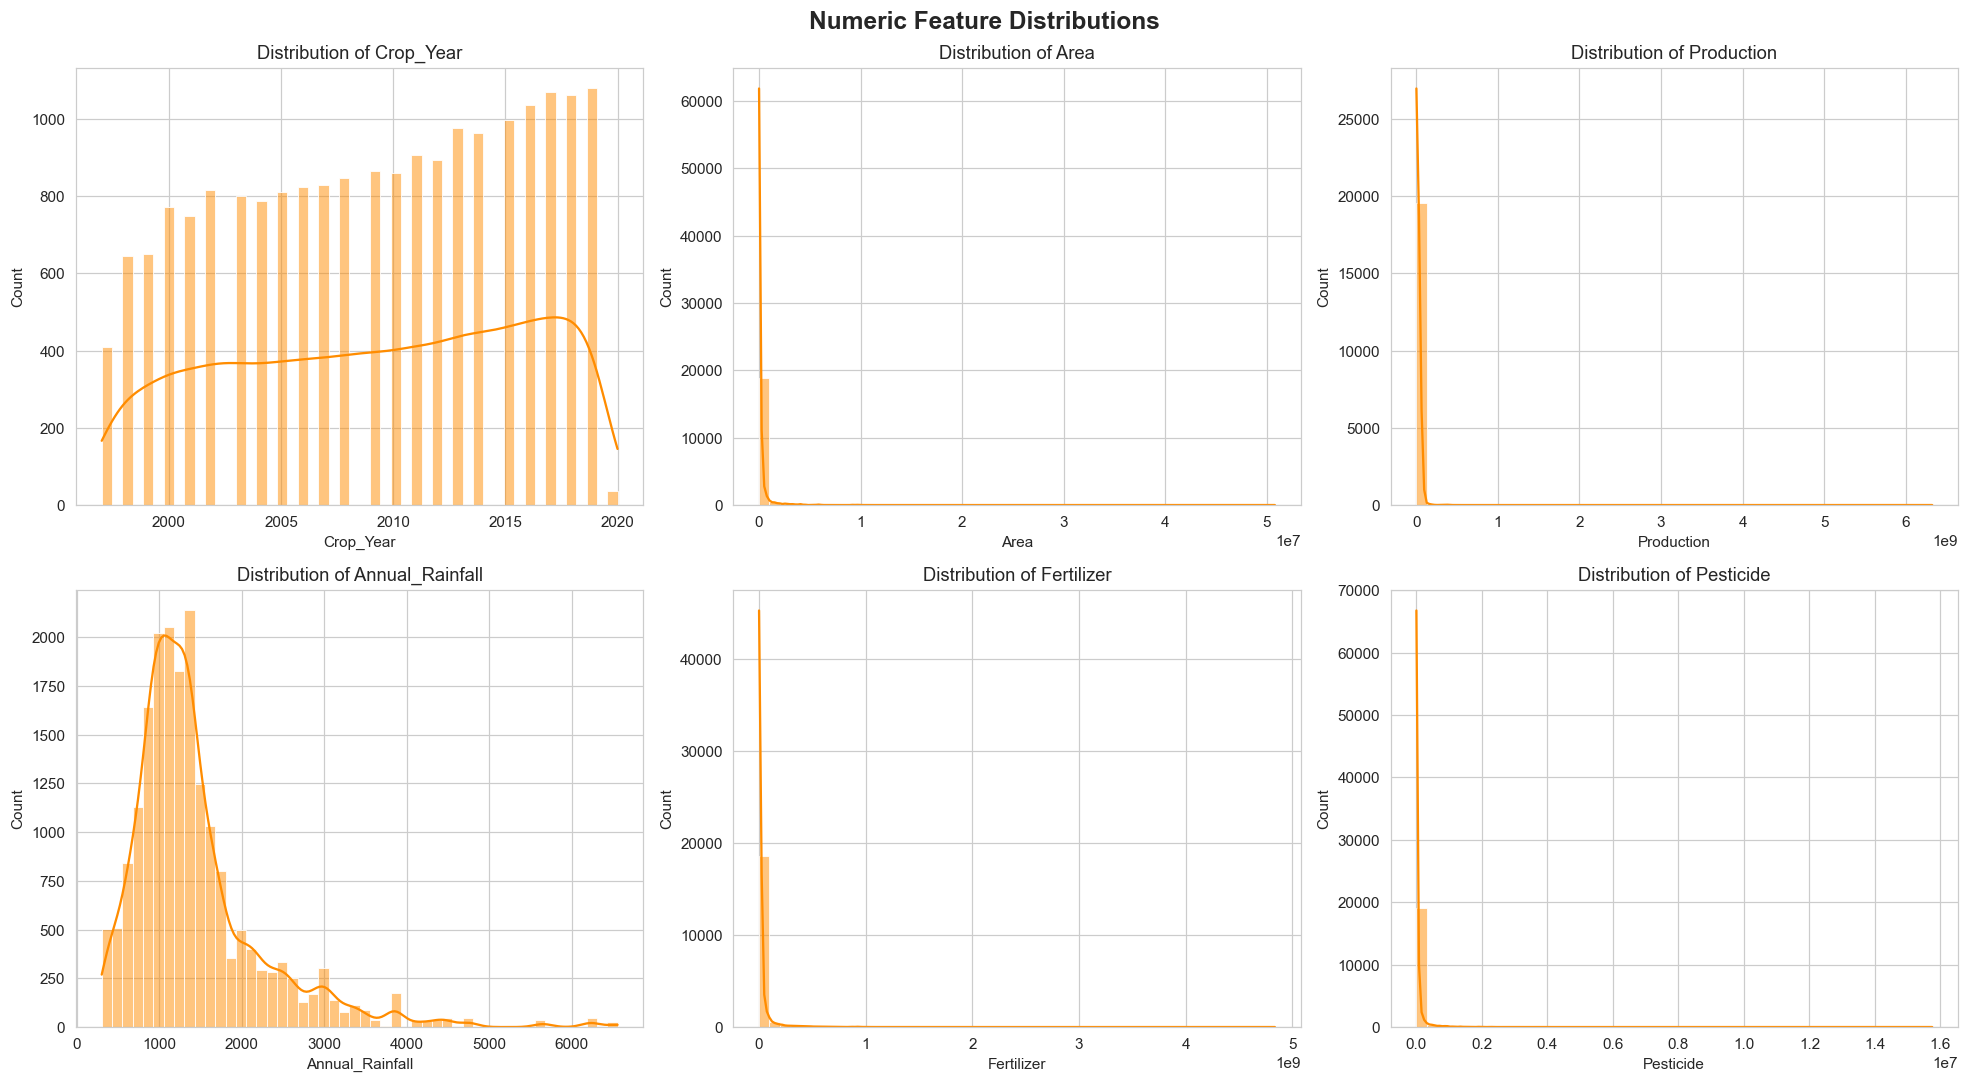

In [6]:
# 2b. Numeric feature distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    sns.histplot(df[col], bins=50, kde=True, ax=axes[i], color="darkorange")
    axes[i].set_title(f"Distribution of {col}")
plt.suptitle("Numeric Feature Distributions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_numeric_feature_distributions.png")
plt.show()
plt.close()

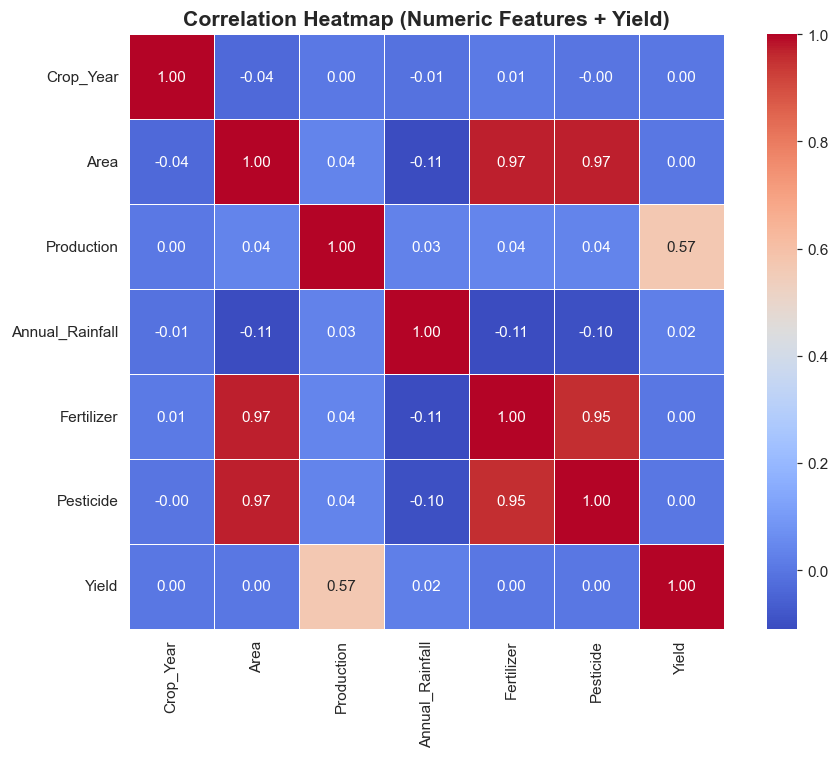

In [7]:
# 2c. Correlation heatmap (numeric features + target)
plt.figure(figsize=(9, 7))
corr = df[NUM_COLS + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.5)
plt.title("Correlation Heatmap (Numeric Features + Yield)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/03_correlation_heatmap.png")
plt.show()
plt.close()

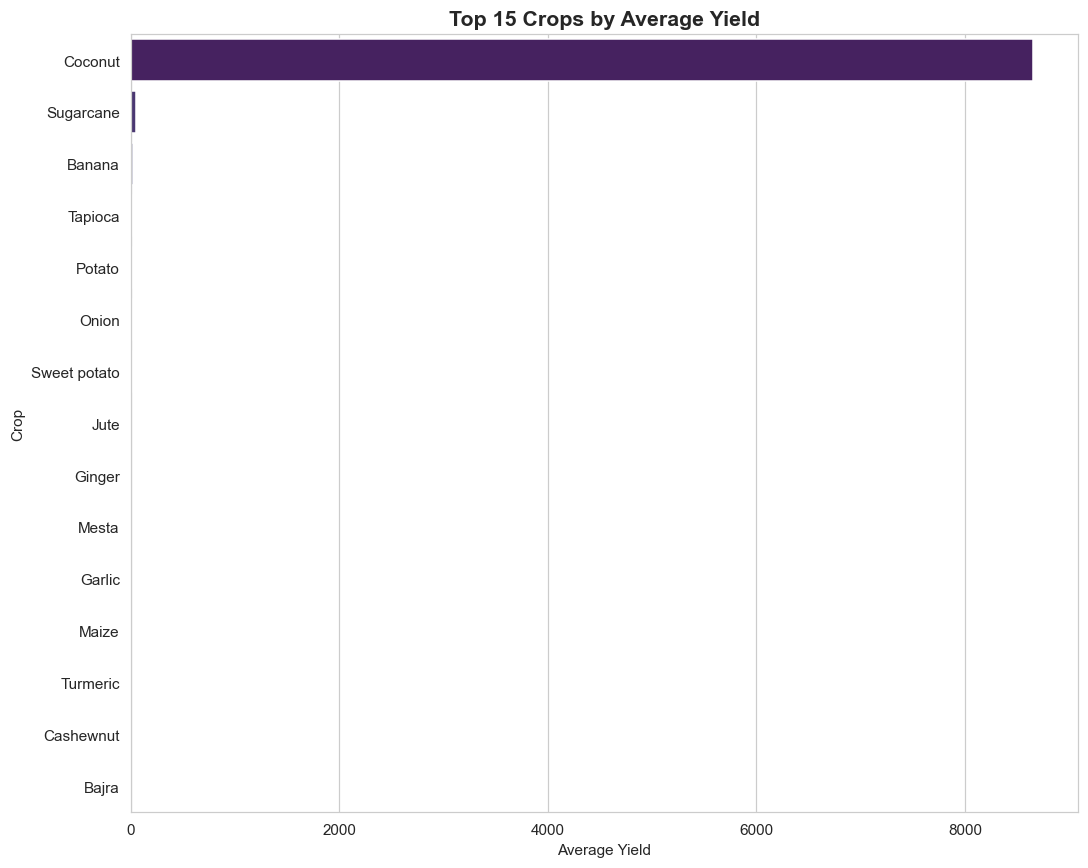

In [8]:
# 2d. Top 15 crops by average yield
plt.figure(figsize=(10, 8))
top_crops = df.groupby("Crop")[TARGET].mean().sort_values(ascending=False).head(15)
sns.barplot(x=top_crops.values, y=top_crops.index, palette="viridis")
plt.title("Top 15 Crops by Average Yield", fontsize=14, fontweight="bold")
plt.xlabel("Average Yield")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_top_crops_by_yield.png")
plt.show()
plt.close()

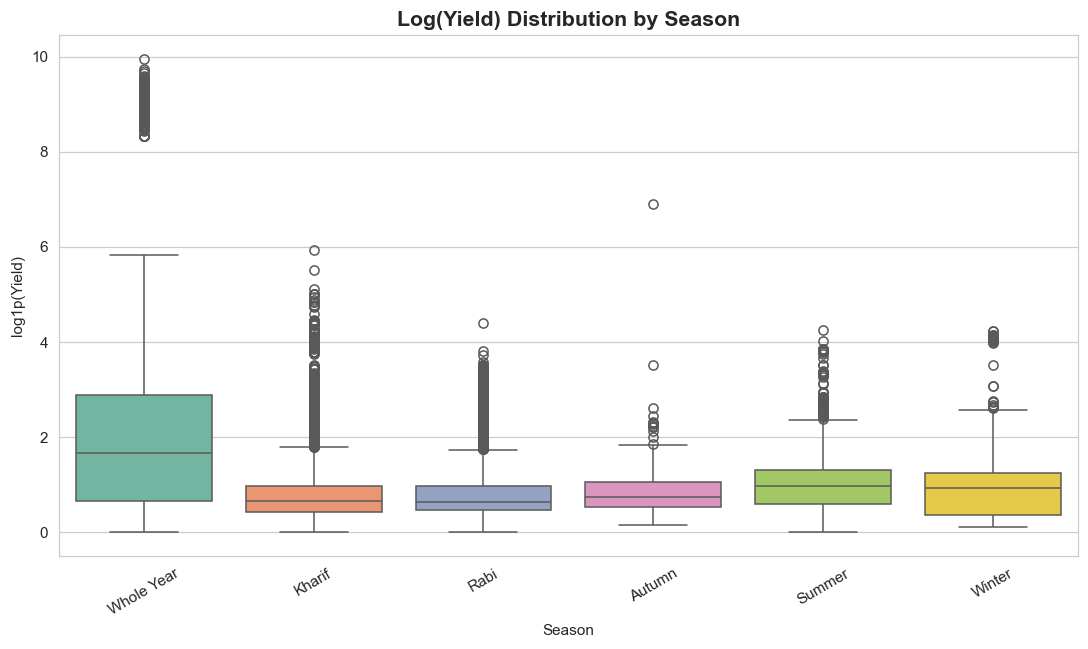

In [9]:
# 2e. Yield by season (boxplot)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Season", y=np.log1p(df[TARGET]), palette="Set2")
plt.title("Log(Yield) Distribution by Season", fontsize=14, fontweight="bold")
plt.ylabel("log1p(Yield)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05_yield_by_season.png")
plt.show()
plt.close()

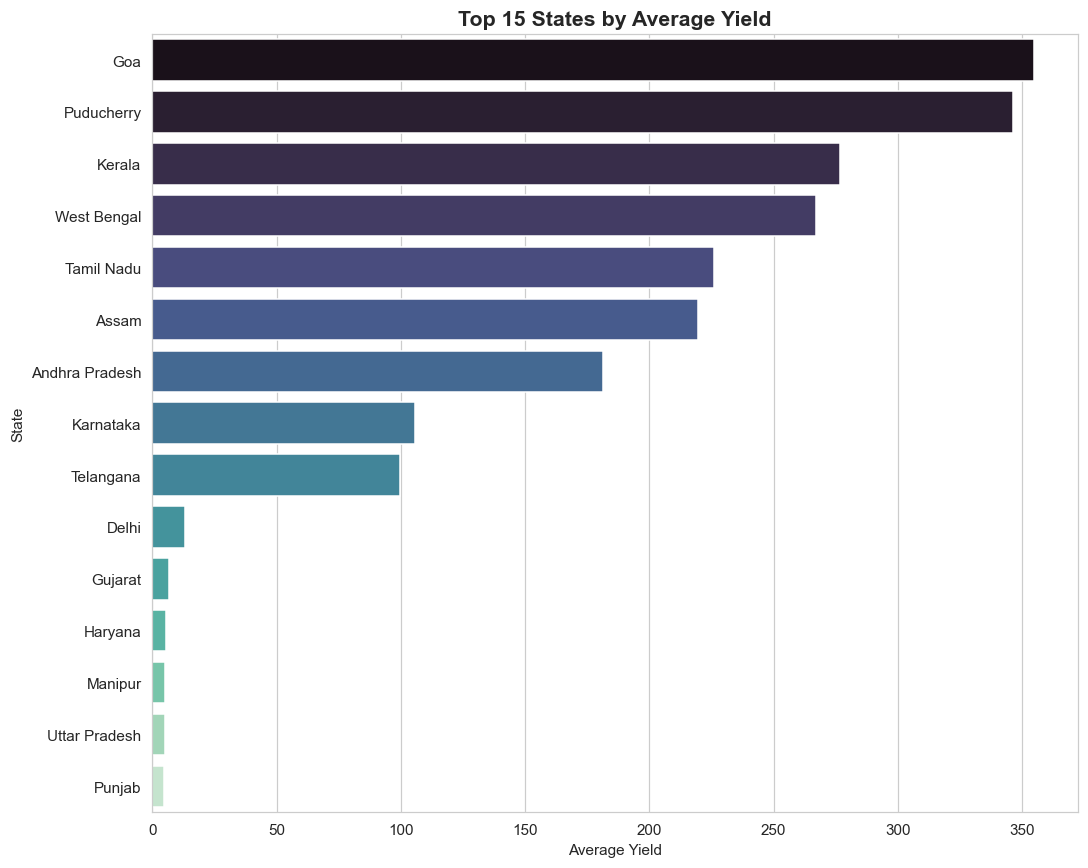

In [10]:
# 2f. Top 15 states by average yield
plt.figure(figsize=(10, 8))
top_states = df.groupby("State")[TARGET].mean().sort_values(ascending=False).head(15)
sns.barplot(x=top_states.values, y=top_states.index, palette="mako")
plt.title("Top 15 States by Average Yield", fontsize=14, fontweight="bold")
plt.xlabel("Average Yield")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_top_states_by_yield.png")
plt.show()
plt.close()

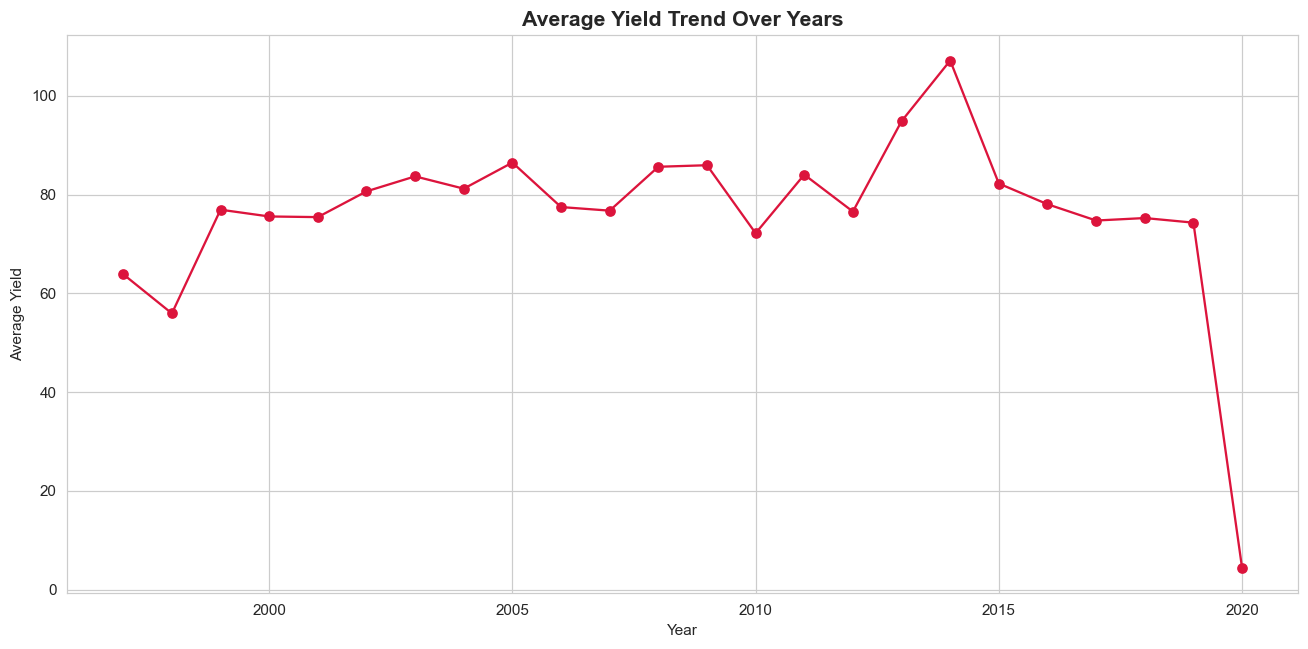

In [11]:
# 2g. Yield trend over years
plt.figure(figsize=(12, 6))
yearly = df.groupby("Crop_Year")[TARGET].mean()
plt.plot(yearly.index, yearly.values, marker="o", color="crimson")
plt.title("Average Yield Trend Over Years", fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Average Yield")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/07_yield_trend_over_years.png")
plt.show()
plt.close()

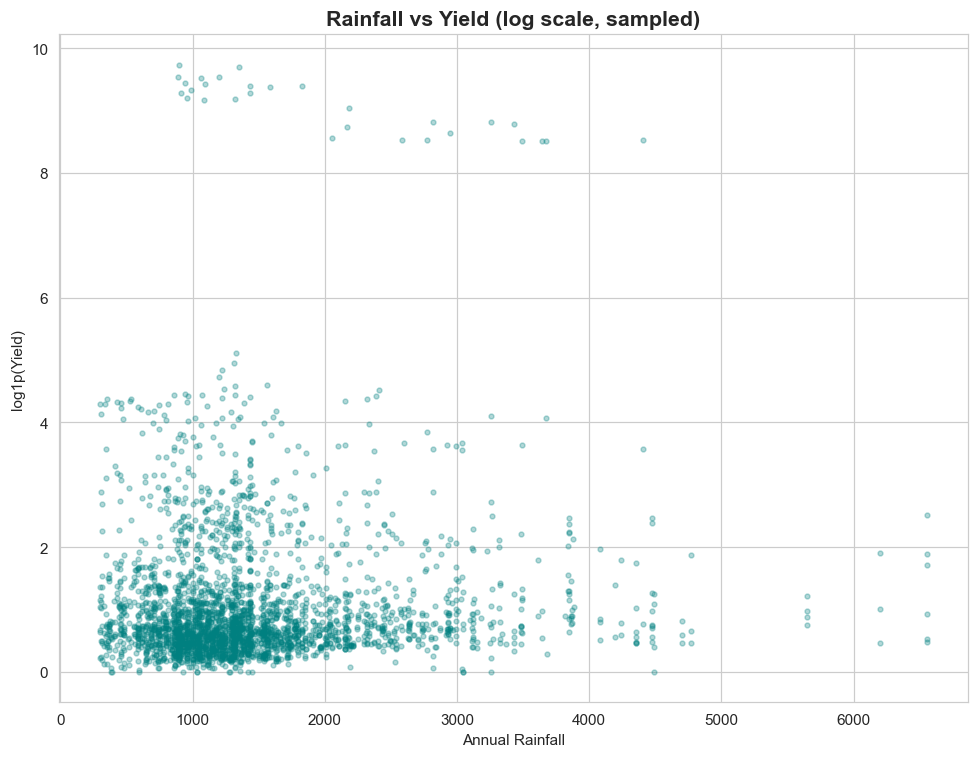

In [12]:
# 2h. Scatter: Annual Rainfall vs Yield (log scale, sampled for clarity)
plt.figure(figsize=(9, 7))
sample = df.sample(min(3000, len(df)), random_state=RANDOM_STATE)
plt.scatter(sample["Annual_Rainfall"], np.log1p(sample[TARGET]), alpha=0.3, s=10, color="teal")
plt.xlabel("Annual Rainfall")
plt.ylabel("log1p(Yield)")
plt.title("Rainfall vs Yield (log scale, sampled)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/08_rainfall_vs_yield.png")
plt.show()
plt.close()

#### PREPROCESSING

In [14]:
df_model = df.copy()
 
encoders = {}
for col in CAT_COLS:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    encoders[col] = le
 
FEATURES = CAT_COLS + NUM_COLS
X = df_model[FEATURES]
y = df_model[TARGET]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")


Train shape: (15751, 9), Test shape: (3938, 9)


#### MODEL TRAINING - XGBoost Regressor

In [15]:
xgb_reg = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
)
 
eval_set = [(X_train, y_train), (X_test, y_test)]
xgb_reg.fit(X_train, y_train, eval_set=eval_set, verbose=False)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


#### CROSS VALIDATION

In [16]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(xgb_reg, X, y, cv=kf, scoring="r2", n_jobs=-1)
print(f"\n5-Fold CV R2: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


5-Fold CV R2: 0.9700 (+/- 0.0229)


#### EVALUATION

In [17]:
y_pred = xgb_reg.predict(X_test)
 
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
 
# MAPE is unstable when true Yield == 0 (division by zero blows it up),
# so compute it only on rows where actual yield is meaningfully non-zero.
mask = y_test > 0.01
mape = mean_absolute_percentage_error(y_test[mask], y_pred[mask])
 
print(f"\nTest MAE  : {mae:.4f}")
print(f"Test RMSE : {rmse:.4f}")
print(f"Test R2   : {r2:.4f}")
print(f"Test MAPE : {mape * 100:.2f}%  (computed on non-zero-yield rows only)")


Test MAE  : 12.8975
Test RMSE : 243.7259
Test R2   : 0.9259
Test MAPE : 95.70%  (computed on non-zero-yield rows only)


#### VISUALIZATIONS - MODEL PERFORMANCE

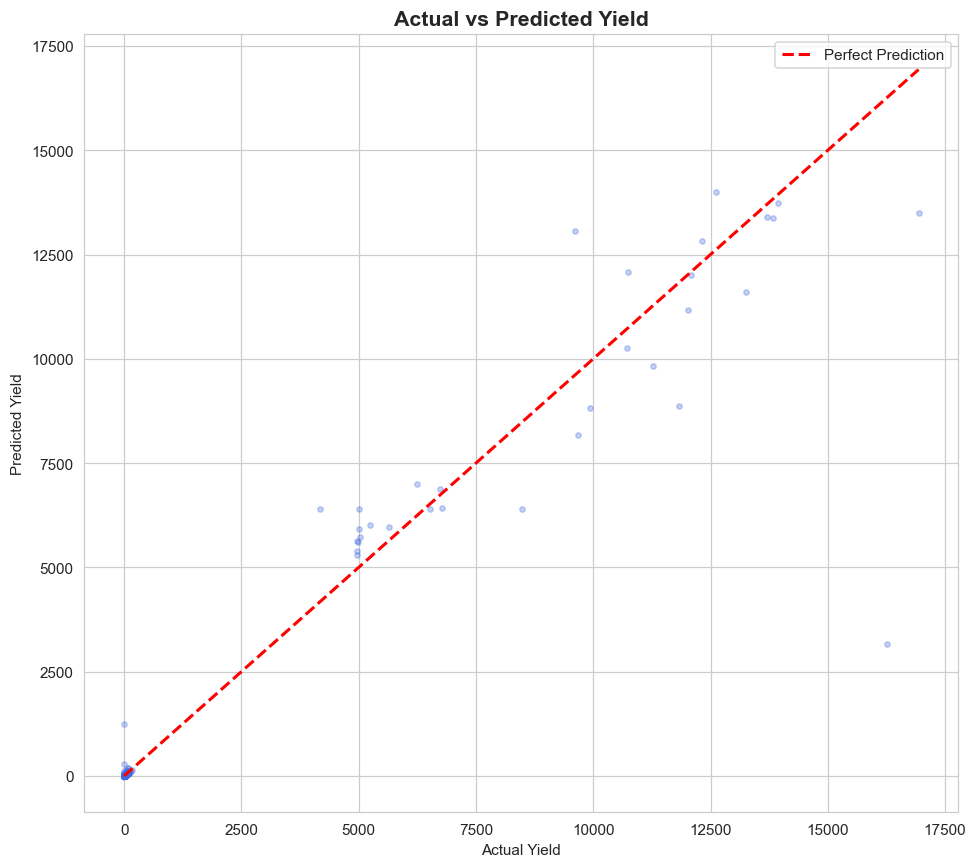

In [18]:
# 7a. Actual vs Predicted scatter
plt.figure(figsize=(9, 8))
plt.scatter(y_test, y_pred, alpha=0.3, s=12, color="royalblue")
max_val = max(y_test.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], "r--", lw=2, label="Perfect Prediction")
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Yield", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/09_actual_vs_predicted.png")
plt.show()
plt.close()

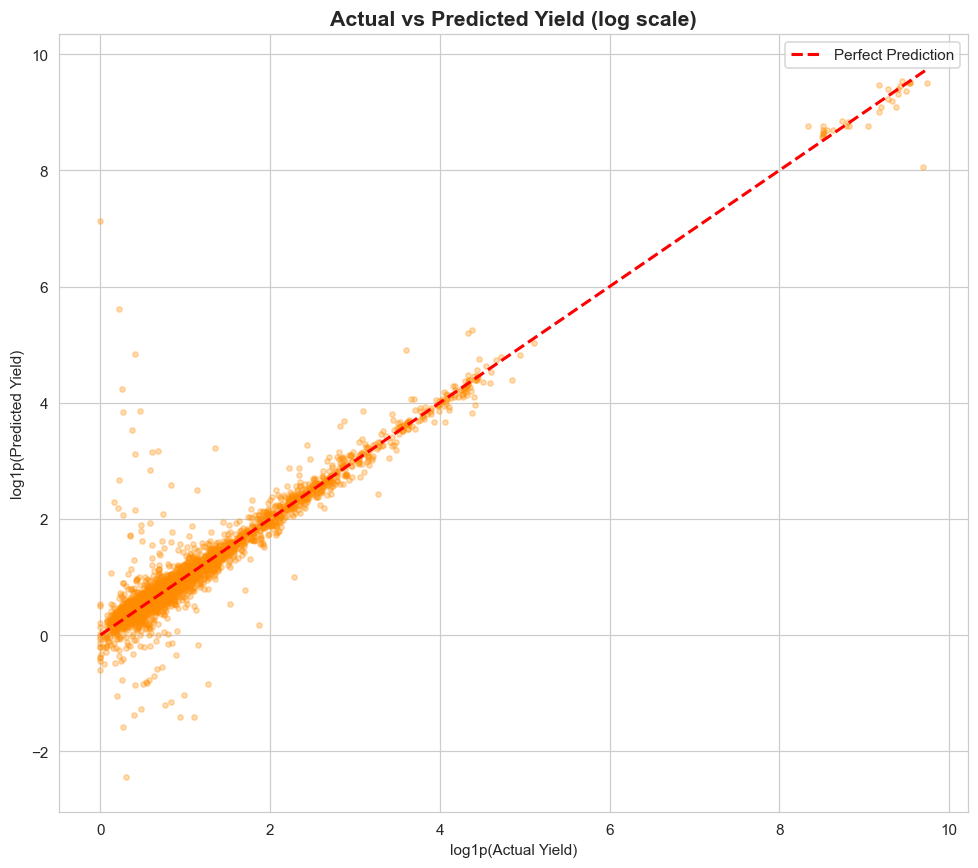

In [19]:
# 7b. Actual vs Predicted (log scale, better for skewed data)
plt.figure(figsize=(9, 8))
plt.scatter(np.log1p(y_test), np.log1p(y_pred), alpha=0.3, s=12, color="darkorange")
max_log = max(np.log1p(y_test).max(), np.log1p(y_pred).max())
plt.plot([0, max_log], [0, max_log], "r--", lw=2, label="Perfect Prediction")
plt.xlabel("log1p(Actual Yield)")
plt.ylabel("log1p(Predicted Yield)")
plt.title("Actual vs Predicted Yield (log scale)", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/10_actual_vs_predicted_log.png")
plt.show()
plt.close()

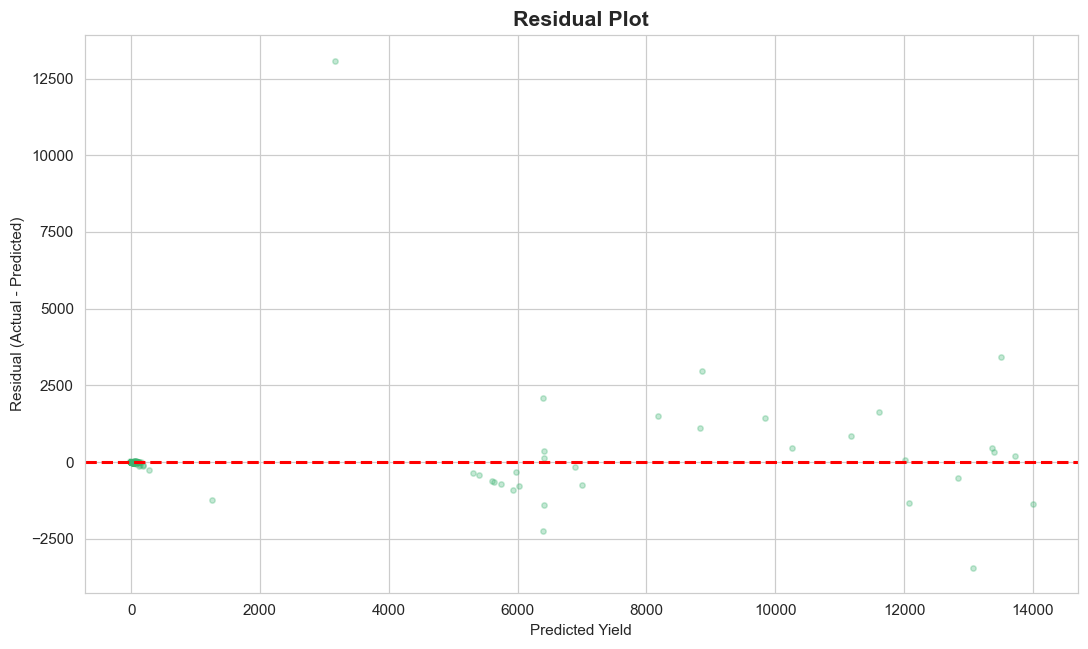

In [20]:
# 7c. Residuals plot
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.3, s=12, color="mediumseagreen")
plt.axhline(0, color="red", linestyle="--", lw=2)
plt.xlabel("Predicted Yield")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/11_residuals.png")
plt.show()
plt.close()

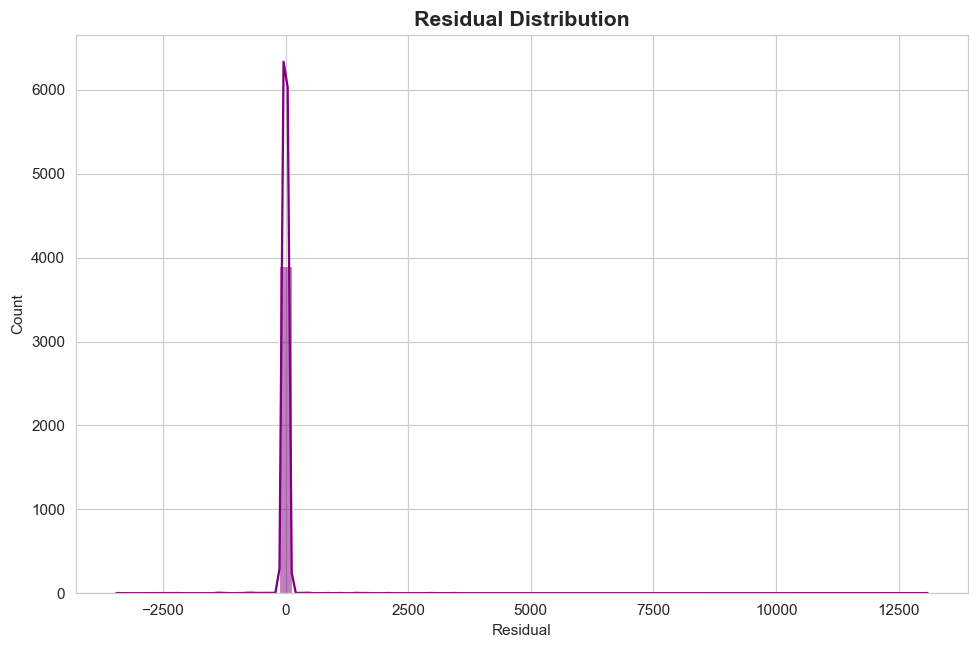

In [21]:
# 7d. Residual distribution
plt.figure(figsize=(9, 6))
sns.histplot(residuals, bins=60, kde=True, color="purple")
plt.title("Residual Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Residual")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/12_residual_distribution.png")
plt.show()
plt.close()

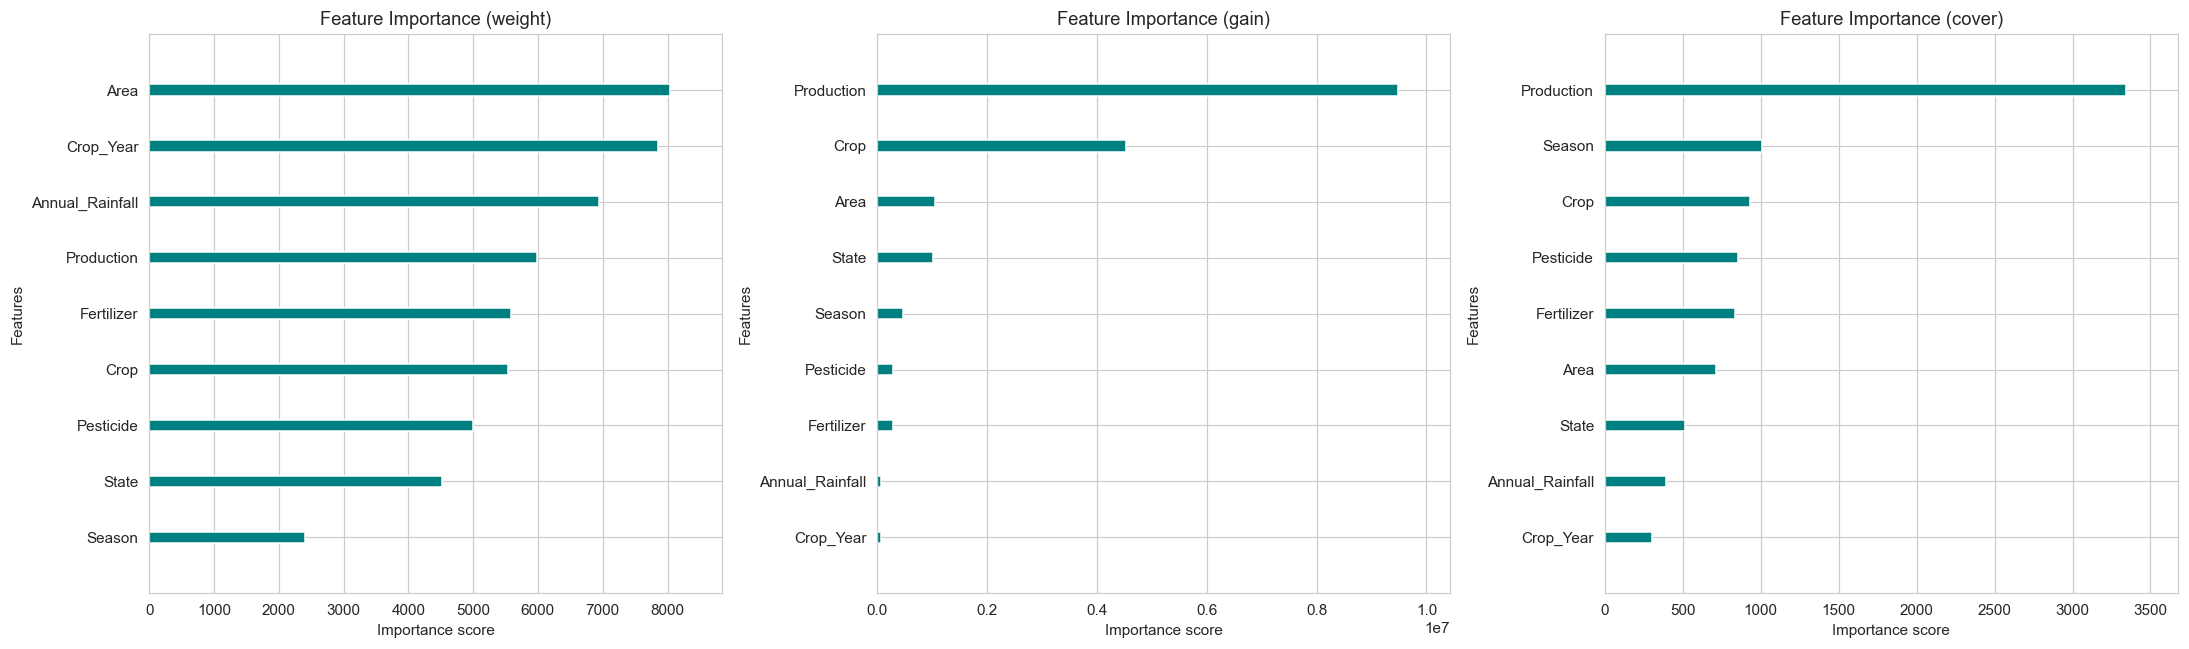

In [22]:
# 7e. Feature Importance (multiple types)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
importance_types = ["weight", "gain", "cover"]
for ax, imp_type in zip(axes, importance_types):
    xgb.plot_importance(xgb_reg, importance_type=imp_type, ax=ax,
                         title=f"Feature Importance ({imp_type})",
                         color="teal", show_values=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/13_feature_importance.png")
plt.show()
plt.close()

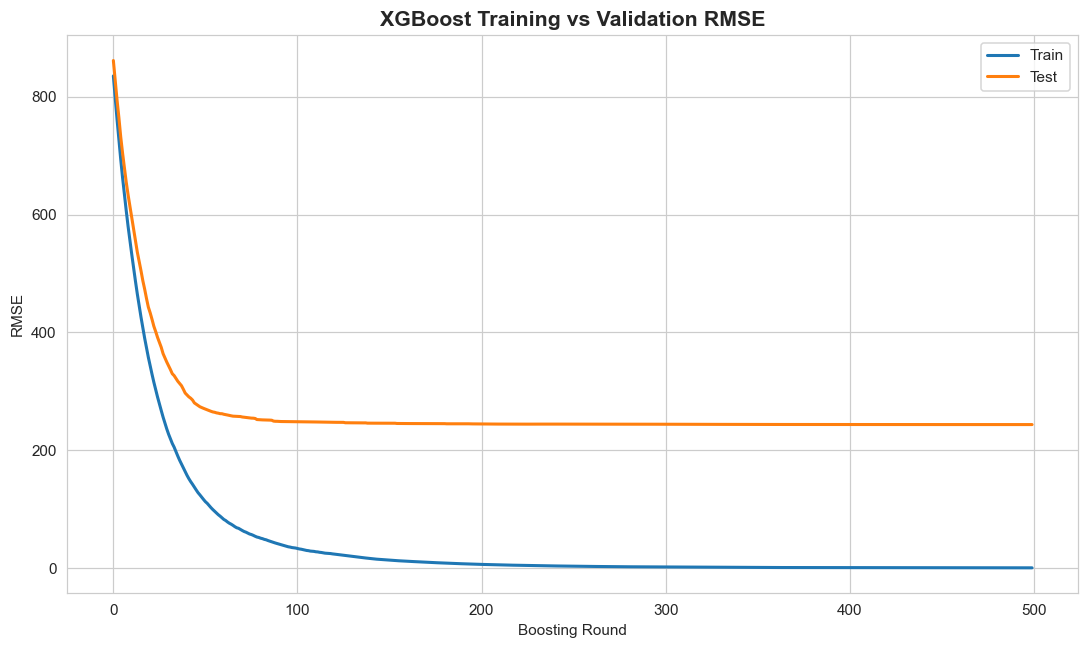

In [23]:
# 7f. Training vs Validation loss curve
results = xgb_reg.evals_result()
epochs = len(results["validation_0"]["rmse"])
x_axis = range(epochs)
plt.figure(figsize=(10, 6))
plt.plot(x_axis, results["validation_0"]["rmse"], label="Train", linewidth=2)
plt.plot(x_axis, results["validation_1"]["rmse"], label="Test", linewidth=2)
plt.xlabel("Boosting Round")
plt.ylabel("RMSE")
plt.title("XGBoost Training vs Validation RMSE", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/14_training_curve.png")
plt.show()
plt.close()

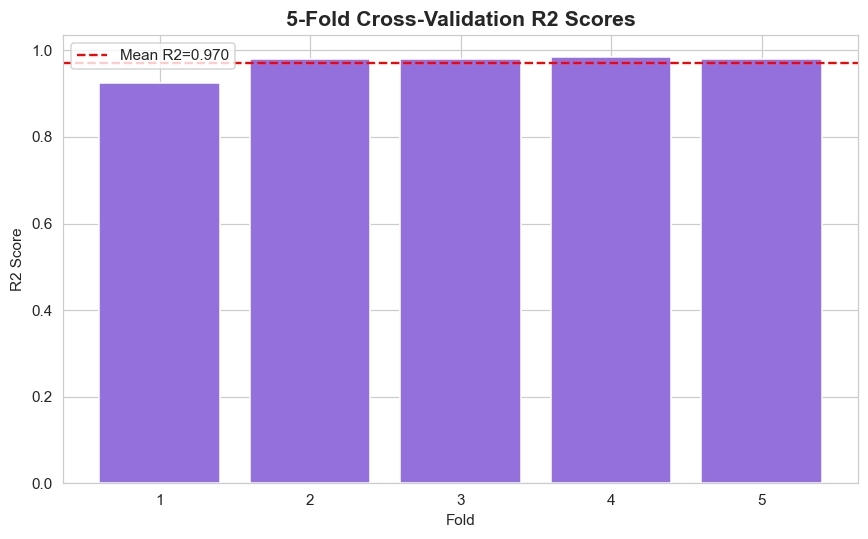

In [24]:
# 7g. CV R2 score distribution
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(cv_scores) + 1), cv_scores, color="mediumpurple")
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean R2={cv_scores.mean():.3f}")
plt.xlabel("Fold")
plt.ylabel("R2 Score")
plt.title("5-Fold Cross-Validation R2 Scores", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/15_cv_scores.png")
plt.show()
plt.close()

#### SAVE MODEL + ARTIFACTS (.pkl)

In [25]:
with open(f"{OUT_DIR}/xgboost_yield_model.pkl", "wb") as f:
    pickle.dump(xgb_reg, f)
 
with open(f"{OUT_DIR}/label_encoders.pkl", "wb") as f:
    pickle.dump(encoders, f)
 
print("\nModel saved at:", os.path.abspath(f"{OUT_DIR}/xgboost_yield_model.pkl"))
print("Label encoders saved at:", os.path.abspath(f"{OUT_DIR}/label_encoders.pkl"))
 
print("\nDone! Summary:")
print(f"  Test R2:   {r2:.4f}")
print(f"  Test MAE:  {mae:.4f}")
print(f"  Test RMSE: {rmse:.4f}")
print(f"  CV R2:     {cv_scores.mean():.4f}")


Model saved at: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\crop_yield\outputs\xgboost_yield_model.pkl
Label encoders saved at: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\crop_yield\outputs\label_encoders.pkl

Done! Summary:
  Test R2:   0.9259
  Test MAE:  12.8975
  Test RMSE: 243.7259
  CV R2:     0.9700
